In [9]:
import pandas as pd
from google.colab import files
uploaded=files.upload()
df=pd.read_csv("diabetes.csv")
print(df.head())

Saving diabetes.csv to diabetes.csv
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [11]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [14]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [15]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df['Outcome'].value_counts()

,count
Outcome,
0,500
1,268


In [21]:
X=df.drop('Outcome',axis=1)
y=df['Outcome']
print(X.shape)
print(y.shape)
X.head()
y.head()

(768, 8)
(768,)


,Outcome
0,1
1,0
2,1
3,0
4,1


In [25]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(614, 8)
(154, 8)
(614,)
(154,)


In [28]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)
X_test[:5]

array([[ 0.96054099,  1.20788789, -0.29601471, -1.31138021, -0.73076636,
        -0.58221684, -0.55579092,  0.56103382],
       [ 1.86648903, -1.67775979,  1.98813468,  0.14031779, -0.27558248,
         0.44897876, -0.58306107,  1.15306018],
       [-0.5493724 ,  0.03460257,  0.3565994 ,  0.392787  ,  1.12712704,
         0.499902  ,  0.01688223, -0.6230189 ],
       [ 0.96054099, -0.21908074, -0.29601471, -1.31138021, -0.73076636,
        -0.58221684,  0.77135637,  0.05358266],
       [-0.5493724 , -1.4874973 , -3.77662329, -1.31138021, -0.73076636,
        -4.07045874, -1.13755411, -0.96131967]])

In [33]:
import tensorflow as tf
from tensorflow.keras import layers,initializers
model=tf.keras.Sequential([
    layers.Input(shape=(8,)),
    #hidden layer 1
    layers.Dense(16,activation='relu',
                 kernel_initializer=initializers.HeNormal(),
                 bias_initializer="zeros"),
    #hidden layer 2
    layers.Dense(8,activation='relu',
                 kernel_initializer=initializers.HeNormal(),
                  bias_initializer="zeros"),
    #output layer
    layers.Dense(1,activation='sigmoid')
])
model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
              learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy'])
print("Model compiled successfully!")

Model compiled successfully!


In [35]:
history=model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2)
#

Epoch 1/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.3462 - loss: 1.2830 - val_accuracy: 0.3577 - val_loss: 1.0506
Epoch 2/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3462 - loss: 1.0314 - val_accuracy: 0.3659 - val_loss: 0.8846
Epoch 3/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3462 - loss: 0.8775 - val_accuracy: 0.3821 - val_loss: 0.7796
Epoch 4/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3788 - loss: 0.7781 - val_accuracy: 0.4634 - val_loss: 0.7114
Epoch 5/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5601 - loss: 0.7104 - val_accuracy: 0.6098 - val_loss: 0.6625
Epoch 6/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6721 - loss: 0.6625 - val_accuracy: 0.6992 - val_loss: 0.6274
Epoch 7/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7088 - loss: 0.6279 - val_accuracy: 0.7154 - val_loss: 0.6015
Epoch 8/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7312 - loss: 0.6020 - val_accuracy: 0.7317 -

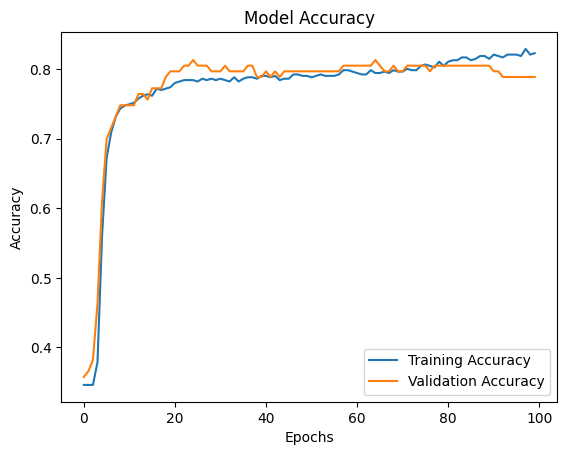

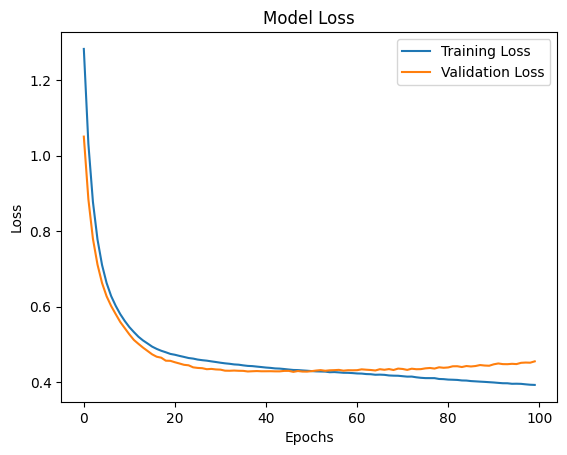

In [36]:
import matplotlib.pyplot as plt

# Plot accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")

plt.legend()
plt.show()

#plot loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Model Loss")

plt.legend()
plt.show()

In [37]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7013 - loss: 0.5173
Test Accuracy: 0.701298713684082
Test Loss: 0.5173160433769226


In [40]:
y_pred = model.predict(X_test)

# Step 2: Convert probabilities into classes (0 or 1)
y_pred_classes = (y_pred >= 0.5).astype(int).ravel()

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


In [41]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_classes)

print(cm)

[[81 19]
 [27 27]]


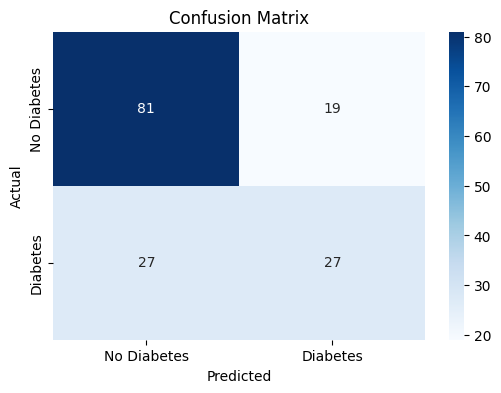

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [43]:
new_person = pd.DataFrame([{
    "Pregnancies": 2,
    "Glucose": 120,
    "BloodPressure": 70,
    "SkinThickness": 20,
    "Insulin": 79,
    "BMI": 25.0,
    "DiabetesPedigreeFunction": 0.5,
    "Age": 30
}])

new_person = new_person[X.columns]

In [44]:
new_person_scaled = scaler.transform(new_person)

probability = model.predict(new_person_scaled, verbose=0)[0][0]

predicted_class = int(probability >= 0.5)

print("Predicted Probability:", probability)
print("Predicted Class:", predicted_class)

if predicted_class == 1:
    print("Model predicts: Diabetes")
else:
    print("Model predicts: No Diabetes")

Predicted Probability: 1.0
Predicted Class: 1
Model predicts: Diabetes


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [46]:
model2=tf.keras.Sequential([
    layers.Input(shape=(8,)),
    #hidden layer 1
    layers.Dense(16,activation='tanh',
                 kernel_initializer=initializers.GlorotNormal(),
                 bias_initializer="zeros"),
    #hidden layer 2
    layers.Dense(8,activation='tanh',
                 kernel_initializer=initializers.GlorotNormal(),
                  bias_initializer="zeros"),
    #output layer
    layers.Dense(1,activation='sigmoid')
])
model2.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
model2.compile(
    optimizer=tf.keras.optimizers.Adam(
              learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [48]:
history2=model2.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2
)

Epoch 1/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.6477 - loss: 0.6430 - val_accuracy: 0.7154 - val_loss: 0.5764
Epoch 2/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7515 - loss: 0.5579 - val_accuracy: 0.7480 - val_loss: 0.5166
Epoch 3/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7576 - loss: 0.5190 - val_accuracy: 0.7805 - val_loss: 0.4895
Epoch 4/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7617 - loss: 0.5008 - val_accuracy: 0.7724 - val_loss: 0.4719
Epoch 5/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7678 - loss: 0.4889 - val_accuracy: 0.7805 - val_loss: 0.4625
Epoch 6/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7658 - loss: 0.4815 - val_accuracy: 0.7805 - val_loss: 0.4521
Epoch 7/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7699 - loss: 0.4760 - val_accuracy: 0.7805 - val_loss: 0.4480
Epoch 8/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7637 - loss: 0.4730 - val_accuracy: 0.7886 -

In [49]:
test_loss, test_accuracy = model2.evaluate(
    X_test,
    y_test
)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7532 - loss: 0.4993
Test Accuracy: 0.7532467246055603
Test Loss: 0.49932682514190674


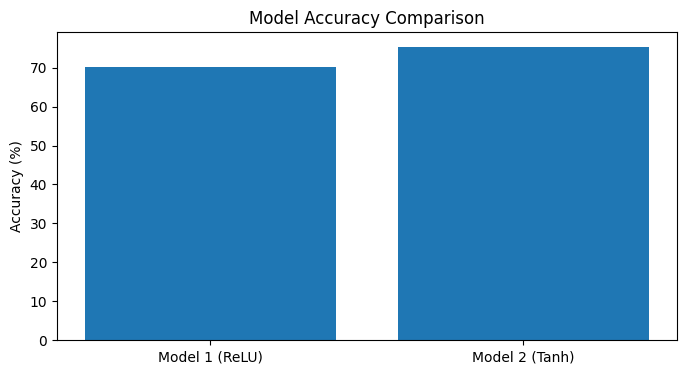

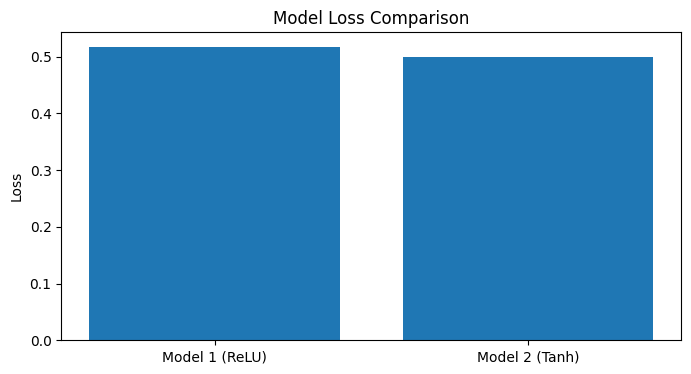

In [50]:
import matplotlib.pyplot as plt

models = ["Model 1 (ReLU)", "Model 2 (Tanh)"]
accuracy = [70.13, 75.32]
loss = [0.5173, 0.4993]

plt.figure(figsize=(8, 4))
plt.bar(models, accuracy)
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")
plt.show()

plt.figure(figsize=(8, 4))
plt.bar(models, loss)
plt.ylabel("Loss")
plt.title("Model Loss Comparison")
plt.show()

In [51]:
# Save Model 1
model.save("diabetes_model1.keras")

# Save Model 2
model2.save("diabetes_model2.keras")

print("Both models saved successfully!")

import joblib

joblib.dump(scaler, "diabetes_scaler.pkl")

print("Scaler saved successfully!")

Both models saved successfully!
Scaler saved successfully!


In [52]:
from google.colab import files

files.download("diabetes_model1.keras")
files.download("diabetes_model2.keras")
files.download("diabetes_scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>